# Day 2: Frequency Analysis, Outliers and the EDA Report
Applied Data Science Skill Lab, CSE (Data Science), III semester, RV College of Engineering

| Time | Session | Lab experiment |
|---|---|---|
| 9:30 to 11:00 | 1. Frequency tables and distributions | 1.3 (first half) |
| 11:30 to 1:00 | 2. Outlier detection | 1.3 |
| 2:00 to 4:00 | 3. EDA summary report | 1.4 |

We use the same dataset as Day 1: Bengaluru House Price Data. Each row is one property listing. `price` is in lakhs of rupees (1 lakh = 100,000).

Cells marked **Exercise** are for you to do. Each needs one or two lines of code. Do them in the empty cell under the exercise.

## Setup

Run this cell first. In Colab it asks you to upload `Bengaluru_House_Data.csv`.

In [1]:
import os, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid")

FILE = "Bengaluru_House_Data.csv"
DATA_URL = "/kaggle/input/datasets/amitabhajoy/bengaluru-house-price-data/Bengaluru_House_Data.csv"   # optional: paste a direct link to the CSV (Drive/GitHub raw) if your class cannot upload files

if not os.path.exists(FILE):
    if DATA_URL:
        pd.read_csv(DATA_URL).to_csv(FILE, index=False)
    else:
        try:                                   # Google Colab: pop up an upload box
            from google.colab import files
            print("Upload Bengaluru_House_Data.csv ...")
            files.upload()
        except ImportError:
            raise FileNotFoundError(f"Place {FILE} in the same folder as this notebook.")
print("Data file ready:", os.path.exists(FILE))

Data file ready: True


## Load and tidy the data

On Day 1 we cleaned this data step by step. Here the same cleaning is done in a few lines, so that today starts from the same table.

One difference from Day 1: values in `total_sqft` that are ranges (like `2100 - 2850`) or have units (like `34.46Sq. Meter`) are left as missing here, to keep the code short.

In [2]:
raw = pd.read_csv(FILE)
df = raw.copy()

In [3]:
#finding problem rows
#\s{2,}	Two or more consecutive whitespace characters
print("BEFORE SPACE REMOVAL")
problem_rows= df[df['location'].str.contains(r'^\s|\s$|\s{2,}', na=False,regex=True)]
print(problem_rows.head())

BEFORE SPACE REMOVAL
                area_type   availability              location       size  society total_sqft  bath  balcony  price
24   Super built-up  Area         18-Nov           Thanisandra       1 RK  Bhe 2ko        510  1.00     0.00  25.25
41   Super built-up  Area         19-Dec        Sarjapur  Road      3 BHK  Soini T       1254  3.00     2.00  38.00
92   Super built-up  Area  Ready To Move        Mysore Highway      3 BHK      NaN       1450  2.00     2.00  70.00
115        Built-up  Area  Ready To Move        Sarjapur  Road  3 Bedroom  Cetattu       2497  3.00     2.00 140.00
152  Super built-up  Area         18-May   Devarachikkanahalli      3 BHK      NaN       1250  2.00     3.00  44.00


In [4]:
# remove extra spaces inside text columns
df["area_type"] = df["area_type"].str.split().str.join(" ")
df["location"] = df["location"].str.split().str.join(" ")


# remove duplicate rows
df = df.drop_duplicates()

# total_sqft: text to number (anything that is not a plain number becomes NaN)
df["total_sqft"] = pd.to_numeric(df["total_sqft"], errors="coerce")

# bedrooms as a number: "2 BHK" becomes 2
df["bhk"] = df["size"].str.split().str[0].astype(float)

# price per square foot in rupees (price is in lakhs)
df["price_per_sqft"] = df["price"] * 100000 / df["total_sqft"]

print("Rows and columns:", df.shape)
print("total_sqft left missing:", df["total_sqft"].isna().sum())
print("AFTER SPACE REMOVAL")
problem_rows.head()

Rows and columns: (12790, 11)
total_sqft left missing: 246
AFTER SPACE REMOVAL


,area_type,availability,location,size,society,total_sqft,bath,balcony,price
24,Super built-up Area,18-Nov,Thanisandra,1 RK,Bhe 2ko,510,1.00,0.00,25.25
41,Super built-up Area,19-Dec,Sarjapur Road,3 BHK,Soini T,1254,3.00,2.00,38.00
92,Super built-up Area,Ready To Move,Mysore Highway,3 BHK,NaN,1450,2.00,2.00,70.00
115,Built-up Area,Ready To Move,Sarjapur Road,3 Bedroom,Cetattu,2497,3.00,2.00,140.00
152,Super built-up Area,18-May,Devarachikkanahalli,3 BHK,NaN,1250,2.00,3.00,44.00


---
# Session 1: Frequency analysis and distributions

## Frequency tables

A frequency table counts how many times each value appears. `value_counts()` does this in one line.

In [5]:
df["area_type"].value_counts()

area_type
Super built-up Area    8316
Built-up Area          2398
Plot Area              1989
Carpet Area              87
Name: count, dtype: int64

Add `normalize=True` to get proportions. Multiply by 100 for percentages.

In [6]:
(df["area_type"].value_counts(normalize=True) * 100).round(1)

area_type
Super built-up Area   65.00
Built-up Area         18.70
Plot Area             15.60
Carpet Area            0.70
Name: proportion, dtype: float64

The most frequent category is called the mode. Here it is Super built-up Area, about 65% of all listings. Carpet Area is under 1%, so any statistic for it rests on very few listings.

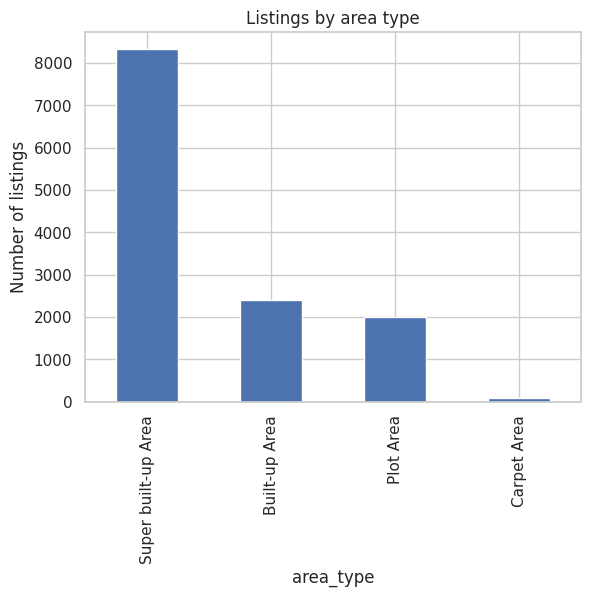

In [7]:
df["area_type"].value_counts().plot(kind="bar")
plt.title("Listings by area type")
plt.ylabel("Number of listings")
plt.show()

---
**Exercise 1.** Use `value_counts()` on the `location` column and show only the top 5.

Hint: Add `.head(5)` at the end.

In [8]:
# Write your code here
df['location'].value_counts().head(5)

location
Whitefield         524
Sarjapur Road      379
Electronic City    289
Kanakpura Road     249
Thanisandra        232
Name: count, dtype: int64

### Frequency table for a number of bedrooms

For numbers with an order, sort by the value instead of by the count. A cumulative column shows how much of the data is covered up to each row.

In [9]:
counts = df["bhk"].value_counts().sort_index()
percent = (counts / counts.sum() * 100).round(1)

table = pd.DataFrame({"count": counts, "percent": percent, "cumulative percent": percent.cumsum()})
table.head(6)

,count,percent,cumulative percent
bhk,,,
1.00,638,5.00,5.00
2.00,5244,41.10,46.10
3.00,4655,36.40,82.50
4.00,1398,10.90,93.40
5.00,350,2.70,96.10
6.00,221,1.70,97.80


2 and 3 BHK together are about 77% of the listings. 1 to 4 BHK cover about 93%. The rest is a long thin tail of large houses, and a few impossible values such as 43 BHK.

---
**Exercise 2.** How many listings have a price above 100 lakh? What percentage of all listings is that?

Hint: `(df['price'] > 100)` gives True or False for each row. `.sum()` counts the True values and `.mean()` gives the share.

In [10]:
# Write your code here


## Grouping numbers into ranges

A price has thousands of different values, so a plain frequency table is not useful. We group prices into ranges with `pd.cut`, then count each range.

In [11]:
bins = [0, 25, 50, 75, 100, 150, 200, 500, 4000]
labels = ["0-25", "25-50", "50-75", "75-100", "100-150", "150-200", "200-500", "500+"]

price_groups = pd.cut(df["price"], bins=bins, labels=labels)
price_groups.value_counts(sort=False)

price
0-25        302
25-50      2997
50-75      3501
75-100     1976
100-150    1785
150-200     771
200-500    1217
500+        241
Name: count, dtype: int64

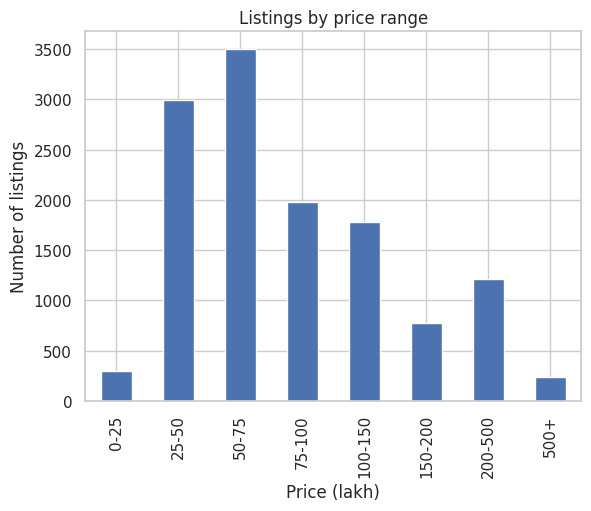

In [12]:
price_groups.value_counts(sort=False).plot(kind="bar")
plt.title("Listings by price range")
plt.xlabel("Price (lakh)")
plt.ylabel("Number of listings")
plt.show()

## Distribution of a number: the histogram

A histogram groups the values into bins and draws one bar per bin. It shows where the values are concentrated and how they spread.

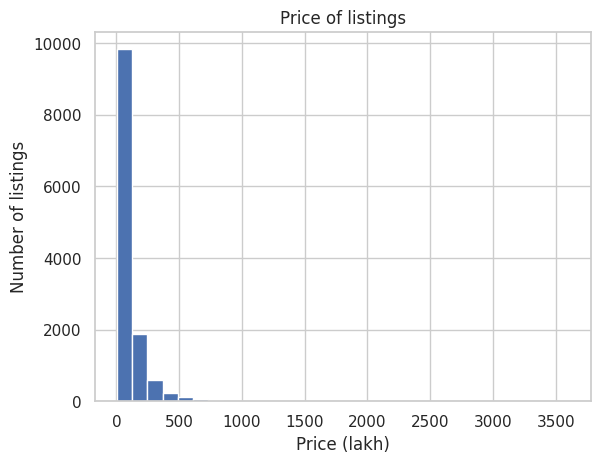

In [13]:
plt.hist(df["price"], bins=30)
plt.title("Price of listings")
plt.xlabel("Price (lakh)")
plt.ylabel("Number of listings")
plt.show()

Most listings are cheap and a few are very expensive, so the right side stretches out to 3,600 lakh. The bars we can read are squeezed on the left. To see the main part, we look only at prices below 400 lakh.

434 listings are 400 lakh or more and are not shown


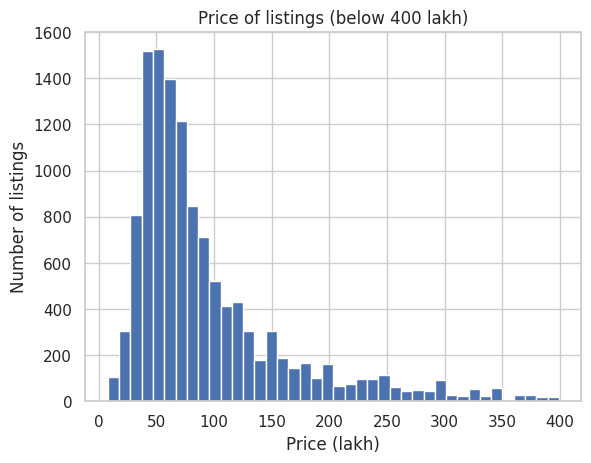

In [14]:
below_400 = df[df["price"] < 400]
print((df["price"] >= 400).sum(), "listings are 400 lakh or more and are not shown")

plt.hist(below_400["price"], bins=40)
plt.title("Price of listings (below 400 lakh)")
plt.xlabel("Price (lakh)")
plt.ylabel("Number of listings")
plt.show()

The number of bins changes how the picture looks. Too few bins hide the shape. Too many show noise. Try several before you decide.

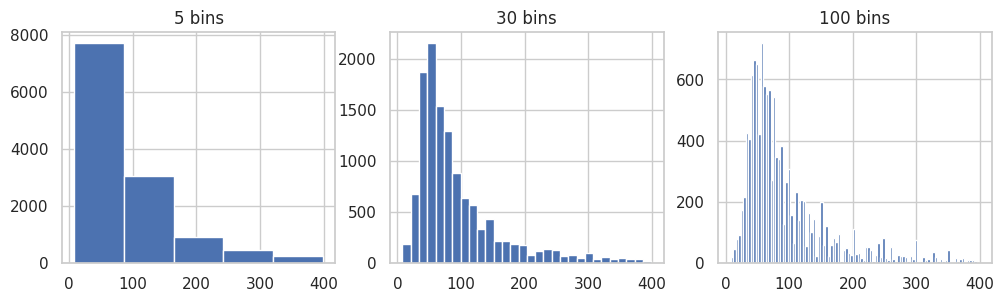

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, b in zip(axes, [5, 30, 100]):
    ax.hist(below_400["price"], bins=b)
    ax.set_title(str(b) + " bins")
plt.show()

The mean is pulled to the right by the expensive listings, so it is larger than the median. A long tail on the right is called right-skewed. A positive skewness value means the same thing.

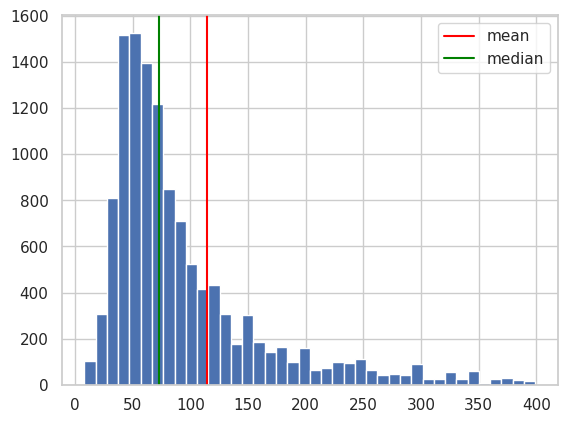

Mean: 114.3  Median: 73.0  Skewness: 7.95


In [16]:
plt.hist(below_400["price"], bins=40)
plt.axvline(df["price"].mean(), color="red", label="mean")
plt.axvline(df["price"].median(), color="green", label="median")
plt.legend()
plt.show()

print("Mean:", round(df["price"].mean(), 1), " Median:", df["price"].median(), " Skewness:", round(df["price"].skew(), 2))

---
**Exercise 3.** Draw a histogram of `total_sqft` for listings with `total_sqft` below 5000. Is it symmetric or skewed?

Hint: Filter first: `df[df['total_sqft'] < 5000]['total_sqft']`. Pass the result to `plt.hist()` and finish with `plt.show()`.

In [17]:
# Write your code here


A common way to handle a right-skewed number is to take its logarithm. The long tail shrinks and the shape becomes easier to read.

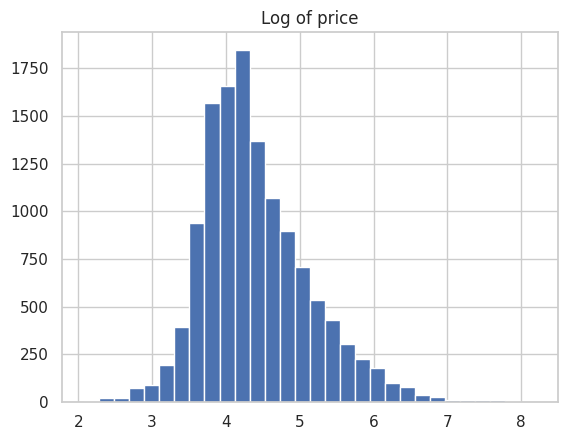

In [18]:
plt.hist(np.log(df["price"]), bins=30)
plt.title("Log of price")
plt.show()

## Comparing groups

`groupby` splits the data into groups and calculates one statistic for each group. We use the median because it is not pulled up by a few expensive listings.

In [19]:
df.groupby("area_type")["price"].median()

area_type
Built-up Area          70.00
Carpet Area            70.00
Plot Area             140.00
Super built-up Area    65.33
Name: price, dtype: float64

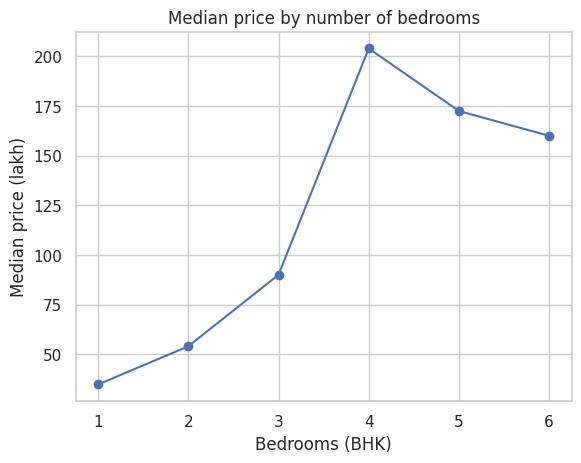

In [20]:
df[df["bhk"] <= 6].groupby("bhk")["price"].median().plot(kind="line", marker="o")
plt.title("Median price by number of bedrooms")
plt.xlabel("Bedrooms (BHK)")
plt.ylabel("Median price (lakh)")
plt.show()

Median price rises from 1 to 4 BHK, then falls for 5 and 6 BHK. Many of the 5 and 6 bedroom listings are plots and independent houses on small sites. A surprising pattern is a reason to look closer, not a conclusion.

---
**Exercise 4.** Find the median `price_per_sqft` for each `area_type`. Which type is the most expensive per square foot?

Hint: Same as the `groupby` above, with a different column.

In [21]:
# Write your code here


---
# Session 2: Outlier detection

An outlier is a value far away from the rest. It can be a typing error, or a real but unusual case. A value that looks unusual is not automatically wrong, so we first flag it, then decide what to do.

## The IQR rule

1. Q1 is the 25th percentile and Q3 is the 75th percentile.
2. IQR = Q3 - Q1. It is the spread of the middle 50% of the data.
3. Lower bound = Q1 - 1.5 x IQR. Upper bound = Q3 + 1.5 x IQR.
4. Values outside the bounds are flagged as potential outliers.

In [22]:
q1 = df["price"].quantile(0.25)
q3 = df["price"].quantile(0.75)
iqr = q3 - q1

lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

print("Q1:", q1, " Q3:", q3, " IQR:", iqr)
print("Lower bound:", lower, " Upper bound:", upper)

Q1: 50.0  Q3: 121.0  IQR: 71.0
Lower bound: -56.5  Upper bound: 227.5


In [23]:
outliers = df[(df["price"] < lower) | (df["price"] > upper)]
print("Outliers:", len(outliers), "out of", len(df), "listings")
print("Share:", round(len(outliers) / len(df) * 100, 1), "%")

Outliers: 1257 out of 12790 listings
Share: 9.8 %


The lower bound is negative, so no listing can be a low outlier. About one listing in ten is flagged on the high side. House prices are naturally right-skewed, so this rule flags many expensive but normal listings. It marks candidates. It does not decide.

## Box plot

The box runs from Q1 to Q3 and the line inside is the median. The whiskers reach the bounds. Dots beyond them are the flagged values.

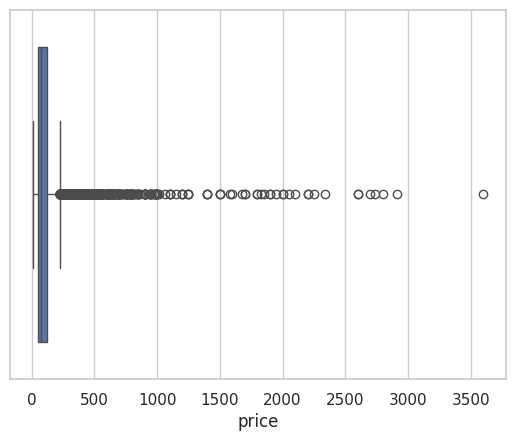

In [24]:
sns.boxplot(x=df["price"])
plt.show()

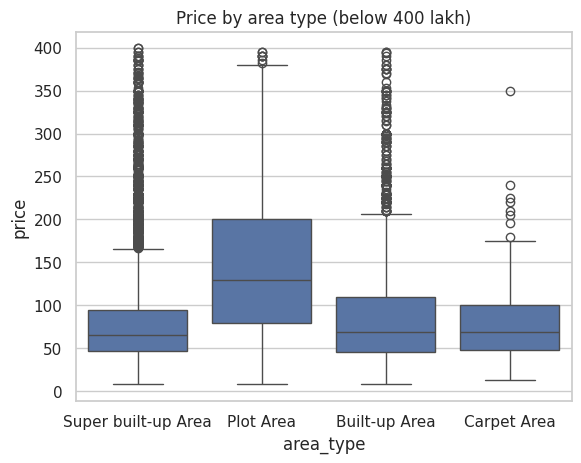

In [25]:
sns.boxplot(x="area_type", y="price", data=df[df["price"] < 400])
plt.title("Price by area type (below 400 lakh)")
plt.show()

## The same steps for another column

Change the name in the first line and run the cell again.

In [26]:
col = "total_sqft"

c_q1 = df[col].quantile(0.25)
c_q3 = df[col].quantile(0.75)
c_iqr = c_q3 - c_q1
low = c_q1 - 1.5 * c_iqr
high = c_q3 + 1.5 * c_iqr

print(col, "bounds:", low, "to", high)
print("Outliers:", ((df[col] < low) | (df[col] > high)).sum())

total_sqft bounds: 222.5 to 2562.5
Outliers: 1092


---
**Exercise 5.** Change `col` in the cell above to `"bath"` and run it. How many outliers do you get? Is a house with 5 bathrooms really an outlier?

Hint: Only the first line of that cell needs to change. The bounds are very close together because most houses have 2 or 3 bathrooms.

In [27]:
# Write your code here


## Look at the flagged rows

Always read the rows. Some will be real, some will be errors.

In [28]:
df.sort_values("price", ascending=False).head(5)[["location", "area_type", "total_sqft", "bath", "price"]]

,location,area_type,total_sqft,bath,price
13067,Defence Colony,Plot Area,"7,150.00",13.00,"3,600.00"
11080,Ashok Nagar,Super built-up Area,"8,321.00",5.00,"2,912.00"
13200,Defence Colony,Plot Area,"8,000.00",6.00,"2,800.00"
11763,Sadashiva Nagar,Plot Area,"9,600.00",7.00,"2,736.00"
3180,Shanthala Nagar,Super built-up Area,"8,321.00",5.00,"2,700.00"


In [29]:
df.sort_values("total_sqft").head(5)[["location", "size", "total_sqft", "price"]]

,location,size,total_sqft,price
4086,Sarjapur Road,4 Bedroom,1.00,120.00
4972,Srirampuram,7 BHK,5.00,115.00
349,Suragajakkanahalli,3 Bedroom,11.00,74.00
1020,Weavers Colony,1 BHK,15.00,30.00
1122,Grihalakshmi Layout,5 Bedroom,24.00,150.00


In [30]:
df.sort_values("bath", ascending=False).head(5)[["location", "size", "bath", "price"]]

,location,size,bath,price
4684,Munnekollal,43 Bedroom,40.00,660.00
1718,2Electronic City Phase II,27 BHK,27.00,230.00
11559,1Kasavanhalli,18 Bedroom,18.00,200.00
3609,Koramangala Industrial Layout,16 BHK,16.00,550.00
3379,1Hanuman Nagar,19 BHK,16.00,490.00


The most expensive listings are large plots in expensive localities such as Defence Colony. They are unusual but believable, so we keep them. A house of 1 square foot, or one with 40 bathrooms, is a typing error. The statistics flagged both. Only our knowledge of houses tells them apart.

---
**Exercise 6.** How many listings have `total_sqft` below 100? A home cannot be that small.

Hint: Compare the column with 100 and use `.sum()` to count the True values.

In [31]:
# Write your code here


## Effect of outliers on the statistics

In [32]:
no_outliers = df[df["price"] <= upper]

compare = pd.DataFrame({
    "with outliers": [df["price"].mean(), df["price"].median(), df["price"].std()],
    "without outliers": [no_outliers["price"].mean(), no_outliers["price"].median(), no_outliers["price"].std()],
}, index=["mean", "median", "std"])
compare.round(1)

,with outliers,without outliers
mean,114.30,80.10
median,73.00,68.00
std,151.50,44.10


The mean and standard deviation change a lot when the outliers are removed. The median changes much less. This is why the median is called a robust statistic.

## What to do with outliers

| Option | When |
|---|---|
| Keep | The value is real, for example a very expensive plot |
| Correct | The right value is known |
| Remove | The value is clearly an error, for example 1 square foot |
| Analyse separately | The listings are a different kind of property |

Whatever you choose, write it down: which rows, which rule, what you decided and why.

---
**Exercise 7.** Draw a box plot of the `bath` column.

Hint: Use `sns.boxplot(x=...)` as before, then `plt.show()`.

In [33]:
# Write your code here


---
# Session 3: EDA summary report

An EDA report tells a reader who has not seen your notebook what the data is, how good it is, and what you found. It has nine parts:

1. Dataset description and source
2. Number of rows and columns
3. Variable names and data types
4. Missing values
5. Descriptive statistics
6. Frequencies and distributions
7. Outliers and what you decided
8. Patterns you found
9. Conclusions, limitations and next steps

Every claim should have a number next to it. Say what you did and what it means.

## Collect the facts

Each cell below gives the numbers for one part of the report.

**Parts 1 and 2: size.** The raw data has this many rows and columns, and this many duplicate rows:

In [34]:
print("Raw rows and columns:", raw.shape)
print("Duplicate rows:", raw.duplicated().sum())
print("Rows after removing duplicates:", len(df))

Raw rows and columns: (13320, 9)
Duplicate rows: 529
Rows after removing duplicates: 12790


**Part 3: variables and types.**

In [35]:
df.dtypes

area_type          object
availability       object
location           object
size               object
society            object
total_sqft        float64
bath              float64
balcony           float64
price             float64
bhk               float64
price_per_sqft    float64
dtype: object

**Part 4: missing values.**

In [36]:
(df.isna().sum() / len(df) * 100).round(1)

area_type         0.00
availability      0.00
location          0.00
size              0.10
society          41.70
total_sqft        1.90
bath              0.60
balcony           4.70
price             0.00
bhk               0.10
price_per_sqft    1.90
dtype: float64

**Part 5: descriptive statistics.**

In [37]:
df[["price", "total_sqft", "bath", "balcony", "bhk"]].describe().round(1)

,price,total_sqft,bath,balcony,bhk
count,"12,790.00","12,544.00","12,717.00","12,185.00","12,774.00"
mean,114.30,"1,565.00",2.70,1.60,2.80
std,151.50,"1,260.30",1.40,0.80,1.30
min,8.00,1.00,1.00,0.00,1.00
25%,50.00,"1,100.00",2.00,1.00,2.00
50%,73.00,"1,280.00",2.00,2.00,3.00
75%,121.00,"1,685.00",3.00,2.00,3.00
max,"3,600.00","52,272.00",40.00,3.00,43.00


**Part 6: frequencies.**

In [38]:
print(df["area_type"].value_counts())
print()
print(df["location"].value_counts().head(5))

area_type
Super built-up Area    8316
Built-up Area          2398
Plot Area              1989
Carpet Area              87
Name: count, dtype: int64

location
Whitefield         524
Sarjapur Road      379
Electronic City    289
Kanakpura Road     249
Thanisandra        232
Name: count, dtype: int64


**Part 7: outliers in price (IQR rule).**

In [39]:
q1, q3 = df["price"].quantile(0.25), df["price"].quantile(0.75)
upper = q3 + 1.5 * (q3 - q1)
print("Upper bound:", upper)
print("Listings above it:", (df["price"] > upper).sum())
print("Areas below 100 sq ft:", (df["total_sqft"] < 100).sum())

Upper bound: 227.5
Listings above it: 1257
Areas below 100 sq ft: 7


**Part 8: patterns.**

In [40]:
print(df.groupby("area_type")["price_per_sqft"].median().round(0))
print()
print(df[df["bhk"] <= 4].groupby("bhk")["price"].median())

area_type
Built-up Area          5,139.00
Carpet Area            6,118.00
Plot Area             10,741.00
Super built-up Area    5,172.00
Name: price_per_sqft, dtype: float64

bhk
1.00    34.75
2.00    54.00
3.00    90.00
4.00   204.00
Name: price, dtype: float64


## A sample report

This is a model of the length and style to aim for. Your report should use your own words and your own findings.

---

**EDA summary report: Bengaluru House Price Data**

**1. Dataset.** Property listings in Bengaluru from Kaggle. Each row is one listing with its area type, availability, location, bedrooms, society, area in square feet, bathrooms, balconies and price in lakhs of rupees. There is no listing date.

**2. Size.** The raw file has 13,320 rows and 9 columns. 529 rows were exact duplicates and were removed, leaving 12,790 rows.

**3. Variables.** `area_type`, `availability`, `location`, `size` and `society` are text. `total_sqft` was also text because some values are ranges or have units. `bath`, `balcony` and `price` are numbers.

**4. Missing values.** `society` is missing in 42% of rows, `balcony` in 5% and `bath` in under 1%. The `society` gaps are mostly plots, which have no society, so the blank has a meaning.

**5. Statistics.** The median price is 73 lakh and the mean is 114 lakh. The middle half of the listings are priced between 50 and 121 lakh. The mean is well above the median, so the median is the better value for a typical listing.

**6. Frequencies and distribution.** 65% of listings are Super built-up Area. Whitefield has the most listings (524). Price has a long right tail: most listings are below 150 lakh, and a few reach 3,600 lakh.

**7. Outliers.** The IQR rule flags 1,257 prices (9.8%) above 227.5 lakh. Most are large plots in expensive areas and were kept. 7 listings have an area below 100 square feet, which is not possible for a home, and one listing has 40 bathrooms. These are likely typing errors.

**8. Patterns.** Plots cost about twice as much per square foot as flats (about 10,700 against 5,200 rupees). Median price rises from 35 lakh for 1 BHK to 204 lakh for 4 BHK.

**9. Conclusions and limitations.** A typical listing is a 2 or 3 BHK flat priced near 73 lakh. Limits: there is no date, so we cannot study price over time. Prices are listing prices, not final sale prices. Some entries are clearly wrong. Next steps: draw scatter plots and a correlation heatmap (Day 3), then build a simple price model (Day 4).

---

## Your report

Write your own report in the cell below, using the nine headings. Keep it to one page. You can copy this skeleton.

```
EDA summary report: <dataset name>
1. Dataset: what the data is, what one row means
2. Size: rows and columns before and after cleaning, duplicates removed
3. Variables: names and types
4. Missing values: which columns, how much, whether it looks random
5. Statistics: mean, median, spread of two or three key columns, in words
6. Frequencies and distribution: most common categories, shape of one number
7. Outliers: rule used, how many, what you decided
8. Patterns: at least 3 findings, each with a number
9. Conclusions and limitations: what you learned, what you do not know, next steps
```

*Write your report here (double-click this cell to edit).*

---
**Exercise 8.** Print the number of rows and columns of the raw data, and the number of duplicate rows in it.

Hint: `raw.shape` and `raw.duplicated().sum()`. Use two `print()` lines.

In [41]:
# Write your code here


---
**Exercise 9.** Which `area_type` has the highest median price? Give the answer in one line of code.

Hint: Take the median price for each type with `groupby`, then add `.idxmax()` to get the name of the largest.

In [42]:
# Write your code here


---
## Check yourself

1. What does `value_counts()` do, and what does `normalize=True` change?
2. Why do we use the median, not the mean, to describe the price?
3. What do Q1, Q3 and the IQR mean? Write the formula for the two bounds.
4. Does a flagged value have to be removed? Give one example you would keep and one you would remove.
5. What does a box plot show?
6. Which parts does an EDA report contain?

## Tomorrow

Day 3 is data visualisation: choosing the right chart, bar and line charts, scatter plots and correlation heatmaps.